In [ ]:
##
!pip install -q "jax==0.4.28" "jaxlib==0.4.28" "numpyro==0.14.0" "numpy<2" "scipy"
## Setup
##
# Standard modules
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import distance  # Needed for RBF

# Modules required for MCMC
import jax
import jax.numpy as jnp  # Use instead of numpy 'np' in numpyro model functions, e.g. RBF
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import arviz as az  # This may give a compatibility warning - this is OK!

# Setup for Jax and numpyro
jax.config.update('jax_platforms', 'cpu')
# Uncomment if necessary (hopefully not) - otherwise, jax defaults to 32-bit
# jax.config.update("jax_enable_x64", True)

In [ ]:
# Import data

import pandas as pd

df = pd.read_csv("bml-component-data.csv")
component_number = df["index"].values
t = df["day"].values
y = df["integrity"].values
ID = df["ID"].drop_duplicates()
components = df["index"].nunique()
X = df[["X1", "X2", "X3", "X4", "X5"]].values


In [ ]:
# Build the baseline model

def baseline_model(component_number, t, y=None, components=None):
    mu_u = numpyro.sample("mu_u", dist.Normal(90.0, 10.0))
    sigma_u = numpyro.sample("sigma_u", dist.HalfNormal(10.0))
    mu_v = numpyro.sample("mu_v", dist.Normal(5.5, 4.5))
    sigma_v = numpyro.sample("sigma_v", dist.HalfNormal(4.5))
    sigma_y = numpyro.sample("sigma_y", dist.HalfNormal(5))
    with numpyro.plate("components", components):
        u = numpyro.sample("u", dist.Normal(mu_u, sigma_u))
        v = numpyro.sample("v", dist.Normal(mu_v, sigma_v))
    mu = u[component_number] * jnp.exp(-v[component_number] * t / 100.0)
    numpyro.sample("obs", dist.Normal(mu, sigma_y), obs=y)

In [ ]:
# Baseline model structure

import graphviz
from numpyro.contrib.module import flax_module
import numpyro.distributions as dist
import numpyro.distributions.constraints as constraints
numpyro.render_model(baseline_model, model_args=(component_number, t, None, components), render_distributions=True,render_params=True)


In [ ]:
#Baseline model statistics

from jax import random

seed = 1

rng = np.random.default_rng(seed)

num_warmup = 2000
num_samples = 2000
rng_key = random.key(0)
NUTS_baseline_kernel = NUTS(baseline_model)
mcmc_baseline = MCMC(NUTS_baseline_kernel,num_warmup=num_warmup,num_samples=num_samples)
mcmc_baseline.run(rng_key,component_number=component_number,t=t,y=y,components=components)
mcmc_baseline.print_summary()

sample: 100%|██████████| 4000/4000 [00:07<00:00, 533.29it/s, 31 steps of size 2.17e-01. acc. prob=0.87]



                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_u     89.71      0.87     89.68     88.26     91.11   1750.51      1.00
      mu_v      3.93      0.23      3.93      3.56      4.30   2731.72      1.00
   sigma_u      5.27      0.82      5.23      3.84      6.51    835.70      1.00
   sigma_v      1.59      0.17      1.57      1.31      1.88   1878.40      1.00
   sigma_y      5.10      0.13      5.10      4.87      5.30   2401.01      1.00
      u[0]     94.00      2.30     94.04     89.98     97.39   4255.45      1.00
      u[1]     87.26      4.26     87.41     80.30     94.21   3433.37      1.00
      u[2]     98.57      2.25     98.55     94.62    102.03   3211.88      1.00
      u[3]     89.29      2.15     89.28     85.47     92.48   3519.83      1.00
      u[4]     87.09      3.92     87.10     81.02     93.69   3843.51      1.00
      u[5]     89.42      4.09     89.46     82.93     96.24   3363.37      1.00
      u[6]     91.59      3

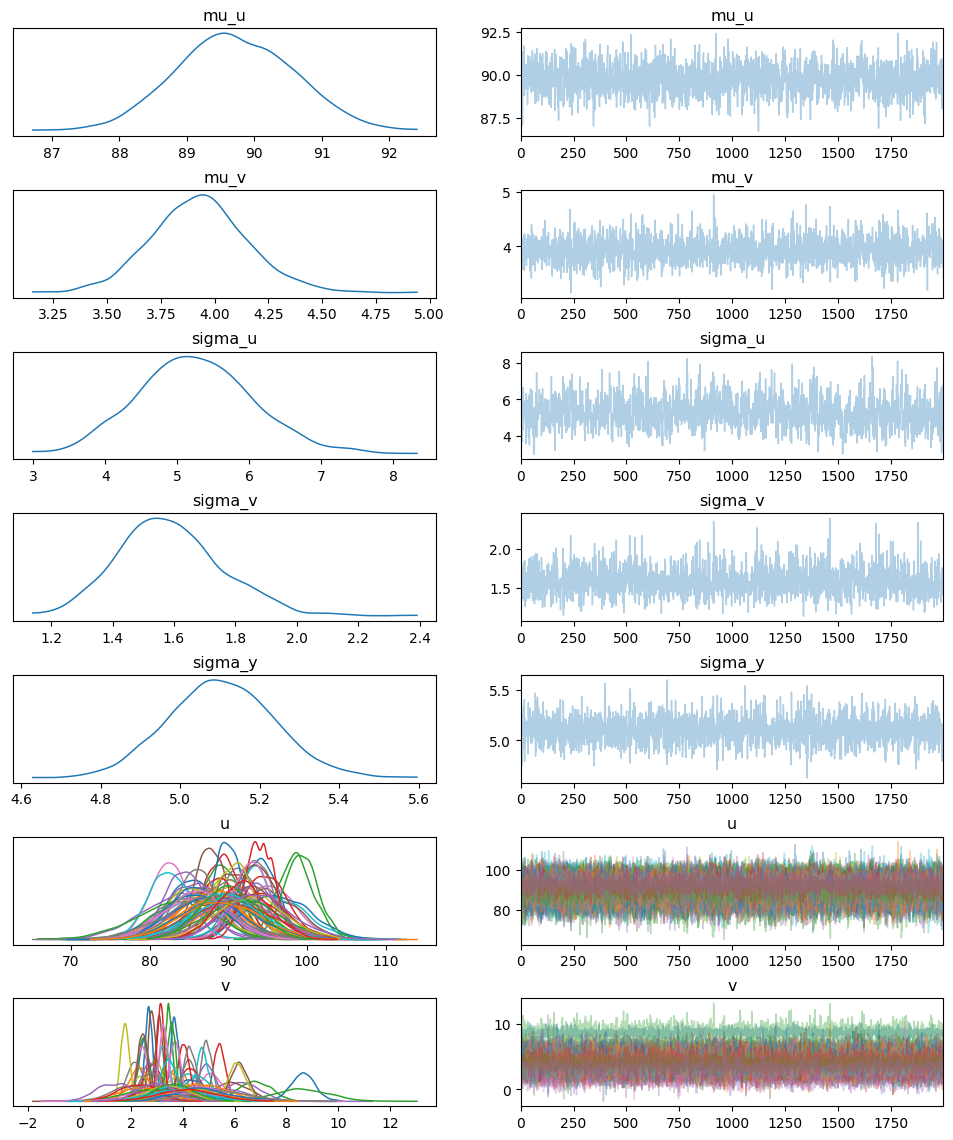

In [ ]:
#Baseline model plots

import arviz as az
az.plot_trace(mcmc_baseline,compact=True)
plt.subplots_adjust(hspace=0.5)

In [ ]:
# Build enhanced model

def enhanced_model(component_number, t, X, y=None, components=None):
    mu_u = numpyro.sample("mu_u", dist.Normal(90.0, 10.0))
    sigma_u = numpyro.sample("sigma_u", dist.HalfNormal(10.0))
    mu_v = numpyro.sample("mu_v", dist.Normal(5.5, 4.5))
    sigma_v = numpyro.sample("sigma_v", dist.HalfNormal(4.5))
    sigma_y = numpyro.sample("sigma_y", dist.HalfNormal(10.0))
    with numpyro.plate("components", components):
        u = numpyro.sample("u", dist.Normal(mu_u, sigma_u))
        v = numpyro.sample("v", dist.Normal(mu_v, sigma_v))
    w = numpyro.sample("w", dist.Normal(0.0, 5).expand([X.shape[1]]))
    mu = u[component_number] * jnp.exp(-(v[component_number] + jnp.sum(X[component_number] * w, axis=1)) * t / 100.0)
    numpyro.sample("obs", dist.Normal(mu, sigma_y), obs=y)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

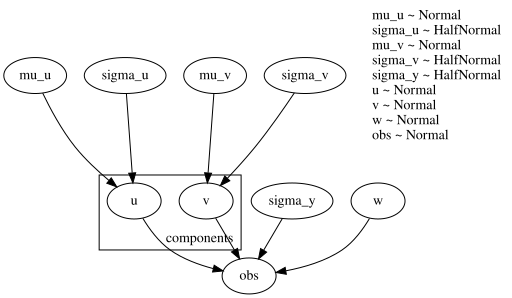

In [ ]:
# Enhanced model structure



numpyro.render_model(enhanced_model, model_args=(component_number, t, X, None, components), render_distributions=True,render_params=True)

In [ ]:
# Enhanced model statistics

from jax import random

seed = 1

rng = np.random.default_rng(seed)

num_warmup = 2000
num_samples = 2000
rng_key = random.key(0)
NUTS_enhanced_kernel = NUTS(enhanced_model)
mcmc_enhanced = MCMC(NUTS_enhanced_kernel,num_warmup=num_warmup,num_samples=num_samples)
mcmc_enhanced.run(rng_key,component_number=component_number,t=t,X=X,y=y,components=components)
mcmc_enhanced.print_summary()

In [ ]:
#Enhanced model plots

import arviz as az
az.plot_trace(mcmc_enhanced,compact=True)
plt.subplots_adjust(hspace=0.5)

In [ ]:
# Predict integrity

def predict(samples, component_number, t, X=None):
    u = samples["u"]
    v = samples["v"]
    sigma_y = samples["sigma_y"]
    u_i = u[:, component_number]
    v_i = v[:, component_number]
    if "w" in samples and X is not None:
        w = samples["w"]
        exp_term = jnp.sum(w * X[component_number], axis=1)
    else:
        exp_term = 0.0
    mu = u_i * jnp.exp(-(v_i + exp_term) * t / 100.0)
    key = jax.random.PRNGKey(0)
    y_pred = mu + sigma_y * jax.random.normal(key, shape=mu.shape)

    return y_pred

In [ ]:
# Compute the probability that it is less than 30

def compute_probabilities_less_than_30(samples, test_components, X=None):
    probs = []
    for i in test_components:
        y_samples = predict(samples, i, t=30.0, X=X)
        prob = jnp.mean(y_samples < 30.0)
        probs.append(prob)

    return jnp.array(probs)

In [ ]:
# Print the probabilities

test_components = jnp.arange(50, 75)
baseline_samples = mcmc_baseline.get_samples()
enhanced_samples = mcmc_enhanced.get_samples()

baseline_probs = compute_probabilities_less_than_30(baseline_samples, test_components, X=X)
enhanced_probs = compute_probabilities_less_than_30(enhanced_samples, test_components, X=X)

print(baseline_probs)
print(enhanced_probs)

ID2 = ID[50:75]
index = np.arange(50, 75, 1)
print(index)

predictions = pd.DataFrame({"ID": ID2, "index": index, "probability": baseline_probs})
predictions.to_csv("predictions.csv", index=False)

[0.55600005 0.919      1.         0.282      0.3555     0.5325
 0.87250006 0.0265     0.78000003 0.48650002 0.74       0.11350001
 0.2045     0.0285     0.         0.6205     0.591      0.92100006
 0.3395     0.55700004 0.82850003 0.702      0.483      0.628
 0.149     ]
[5.41500032e-01 9.17500019e-01 1.00000000e+00 2.65500009e-01
 3.41000021e-01 4.99500036e-01 8.71500015e-01 2.70000007e-02
 7.77500033e-01 4.53000009e-01 7.30500042e-01 1.05500005e-01
 2.03000009e-01 2.25000009e-02 5.00000024e-04 6.05500042e-01
 5.67000031e-01 9.11000073e-01 3.32000017e-01 5.44500053e-01
 8.24000061e-01 7.13500023e-01 4.98500019e-01 6.23500049e-01
 1.36500001e-01]
[50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73
 74]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Compute the model fit for the baseline model

import jax.numpy as jnp

def compute_curves_baseline(samples, component_number, ts):
    u = samples["u"]
    v = samples["v"]
    sigma_y = samples["sigma_y"]
    u_i = u[:, component_number]
    v_i = v[:, component_number]
    ts = jnp.array(ts)
    function_samples = u_i[:, None] * jnp.exp(-v_i[:, None] * ts[None, :] / 100.0)
    function_mean = jnp.mean(function_samples, axis=0)
    function_sd = jnp.std(function_samples, axis=0)
    total_sd = jnp.sqrt(function_sd**2 + jnp.mean(sigma_y**2))

    return function_mean, function_sd, total_sd

In [ ]:
# Compute the model fit for the enhanced model

def compute_curves_enhanced(samples, component_number, ts, X):
    u = samples["u"]
    v = samples["v"]
    w = samples["w"]
    sigma_y = samples["sigma_y"]
    u_i = u[:, component_number]
    v_i = v[:, component_number]
    X_i = X[component_number]
    exp_term = jnp.sum(w * X_i, axis=1)
    ts = jnp.array(ts)
    function_samples = u_i[:, None] * jnp.exp(-(v_i[:, None] + exp_term[:, None]) * ts[None, :] / 100.0)
    function_mean = jnp.mean(function_samples, axis=0)
    function_sd = jnp.std(function_samples, axis=0)
    total_sd = jnp.sqrt(function_sd**2 + jnp.mean(sigma_y**2))

    return function_mean, function_sd, total_sd

In [ ]:
#Plot the model fit for the baseline model

import matplotlib.pyplot as plt

def plot_component_baseline(component_number, samples, t, y, X=None):
    ts = jnp.linspace(0, 60, 100)
    function_mean, function_sd, total_sd = compute_curves_baseline(samples, component_number, ts)
    t_obs = t[component_number]
    y_obs = y[component_number]
    plt.scatter(t_obs, y_obs, color="black")
    plt.plot(ts, function_mean, color="black", label="mean")
    plt.fill_between(ts, function_mean - 1.96 * function_sd, function_mean + 1.96 * function_sd, color="purple", alpha=0.3,
        label="function estimate uncertainty")
    plt.fill_between(ts, function_mean - 1.96 * total_sd, function_mean + 1.96 * total_sd, color="blue", alpha=0.15,
        label="overall uncertainty")
    plt.xlabel("time (days)")
    plt.ylabel("integrity")
    plt.title(f"Component {component_number}")
    plt.xlim(0, 60)
    plt.ylim(0, 100)
    plt.legend()

In [ ]:
#Plot the enhanced model model fit

import matplotlib.pyplot as plt

def plot_component_enhanced(component_number, samples, t, y, X=None):
    ts = jnp.linspace(0, 60, 100)
    function_mean, function_sd, total_sd = compute_curves_enhanced(samples, component_number, t_grid, X = X)
    t_obs = t[component_number]
    y_obs = y[component_number]
    plt.scatter(t_obs, y_obs, color="black")
    plt.plot(ts, function_mean, color="black", label="mean")
    plt.fill_between(ts, function_mean - 1.96 * function_sd, function_mean + 1.96 * function_sd, color="green", alpha=0.3,
        label="function estimate uncertainty")
    plt.fill_between(ts, function_mean - 1.96 * total_sd, function_mean + 1.96 * total_sd, color="blue", alpha=0.15,
        label="overall uncertainty")
    plt.xlabel("time (days)")
    plt.ylabel("integrity")
    plt.title(f"Component {component_number}")
    plt.xlim(0, 60)
    plt.ylim(0, 100)
    plt.legend()

In [ ]:
# Plot and compute the model fits

fig, axes = plt.subplots(4, 2, figsize=(12, 12))
axes = axes.flatten()
plt.subplots_adjust(wspace=0.4, hspace=0.4)
plt.sca(axes[0])
plot_component_baseline(1, baseline_samples, t, y)
plt.sca(axes[1])
plot_component_baseline(51, baseline_samples, t, y)
plt.sca(axes[2])
plot_component_baseline(52, baseline_samples, t, y)
plt.sca(axes[3])
plot_component_baseline(53, baseline_samples, t, y)
plt.sca(axes[4])
plot_component_enhanced(1, enhanced_samples, t, y, X)
plt.sca(axes[5])
plot_component_enhanced(51, enhanced_samples, t, y, X)
plt.sca(axes[6])
plot_component_enhanced(52, enhanced_samples, t, y, X)
plt.sca(axes[7])
plot_component_enhanced(53, enhanced_samples, t, y, X)
plt.show()